# EDA de imágenes (entrenamiento)

Este notebook usa solo las imágenes de entrenamiento de `data/splits.csv`. La única
excepción es la sección 12 (validación adversarial), que usa imágenes de test sin sus
etiquetas. Todos los parámetros se leen de `configs/base.yaml`.

## 1. Carga de la partición

Se carga la partición, se conservan las filas con `split == "train"` y se añaden los
metadatos de esas imágenes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import data, eda, stats
from src.utils import set_seed

2026-11-13 12:49:13.602493: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
cfg = data.load_config()
set_seed(cfg["seed"])
rutas = cfg["paths"]

In [3]:
splits = data.load_splits(rutas["splits_csv"])
meta = data.load_metadata(cfg)
train = (splits[splits["split"] == "train"]
         .merge(meta.drop(columns=["lesion_id", "dx"]), on="image_id", how="left")
         .reset_index(drop=True))

ids_test = set(splits.loc[splits["split"] == "test", "image_id"])
assert (train["split"] == "train").all(), "Hay filas que no son de entrenamiento"
assert ids_test.isdisjoint(train["image_id"]), "Hay imágenes de test en el conjunto de trabajo"
pd.Series({"imágenes de entrenamiento": len(train)}, name="valor").to_frame()

,valor
imágenes de entrenamiento,8584


In [4]:
orden_dx = train["dx"].value_counts().index.tolist()
fuente = cfg["source_column"]
tiene_fuente = data.has_source_column(train, cfg)
rutas_orig = data.image_paths(cfg, train["image_id"])

## 2. Caché

Versiones reducidas de las imágenes de entrenamiento (lado mayor `eda_cache_max_side`,
relación de aspecto conservada) en `data/processed/eda_cache/`. Las que ya existen se
reutilizan.

In [5]:
cache = eda.build_cache(train["image_id"], rutas_orig, rutas["eda_cache_dir"],
                        cfg["eda_cache_max_side"], cfg["eda_cache_format"], cfg["eda_cache_jpeg_quality"])
train["cache_path"] = train["image_id"].map(cache)
pd.Series({"imágenes en caché": int(train["cache_path"].notna().sum())}, name="valor").to_frame()

Caché EDA: 100%|██████████| 8584/8584 [00:00<00:00, 67273.76it/s]


,valor
imágenes en caché,8584


## 3. Inspección visual

`eda_grid_per_class` imágenes aleatorias por clase (semilla fija), con su `image_id` y `dx`.

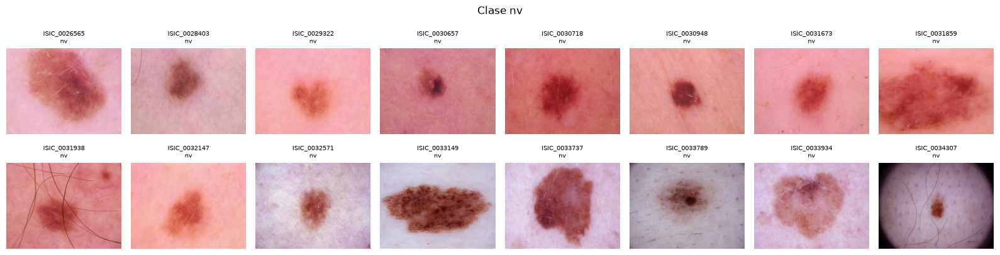

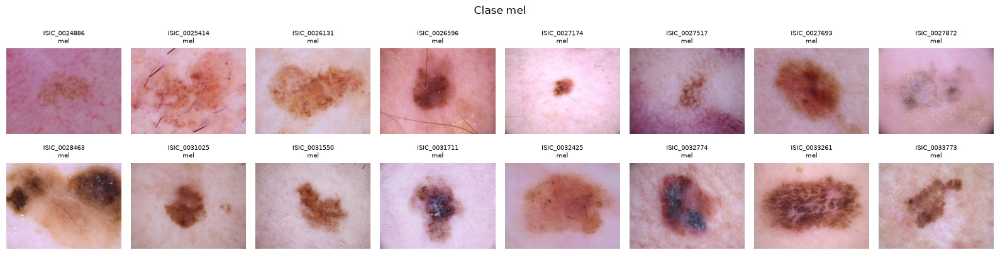

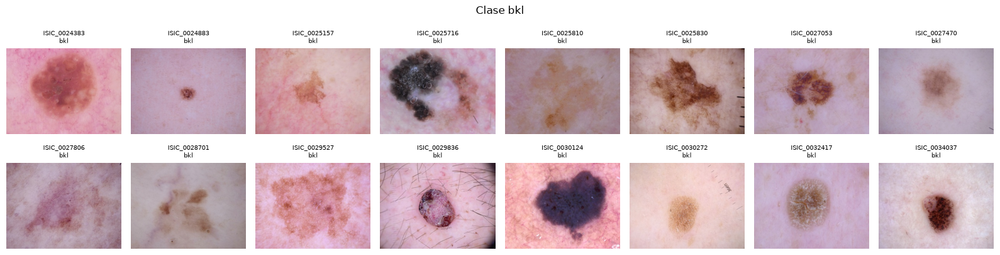

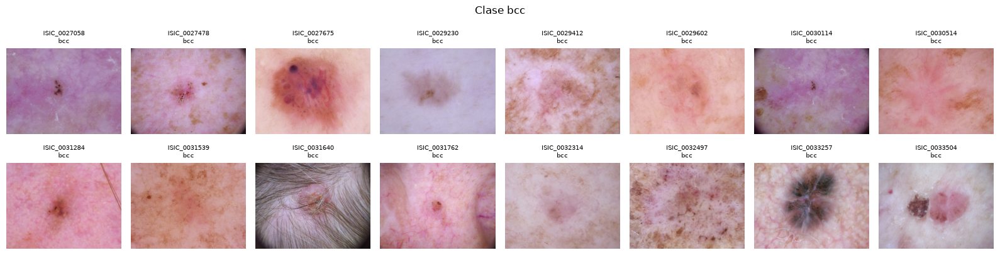

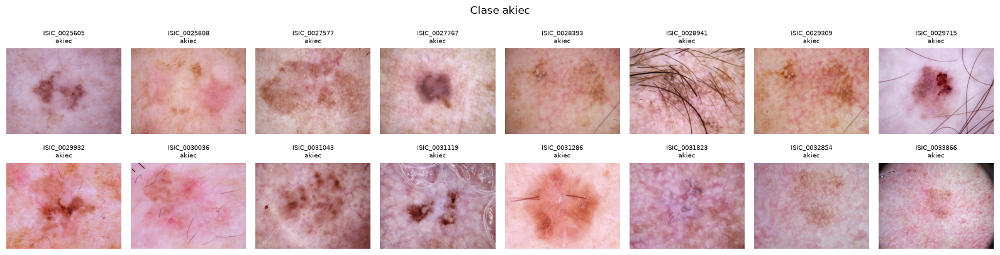

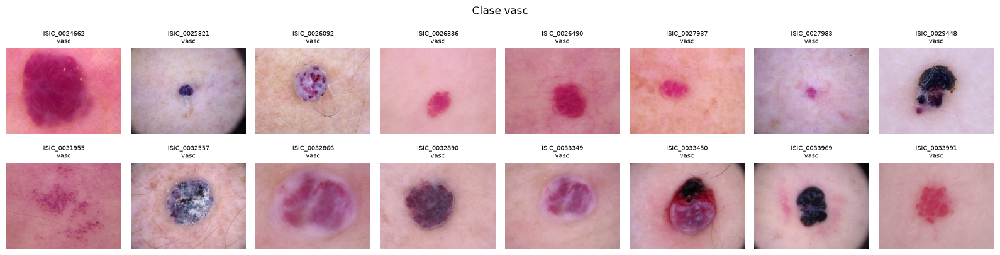

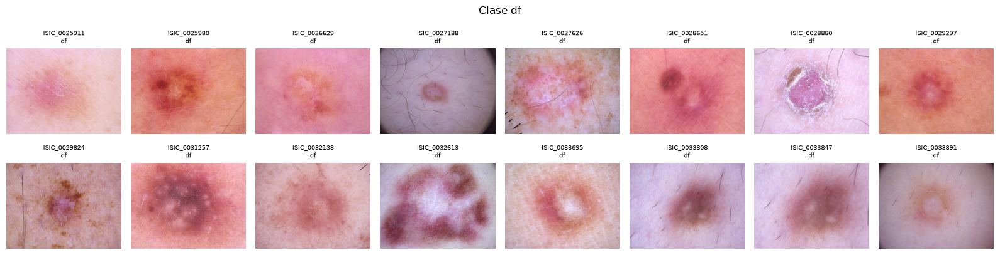

In [6]:
muestra = eda.sample_per_class(train, cfg["eda_grid_per_class"], cfg["seed"])
for dx in orden_dx:
    sub = muestra[muestra["dx"] == dx]
    eda.plot_image_grid(sub["cache_path"], sub["image_id"] + "\n" + sub["dx"],
                        ncols=cfg["eda_grid_ncols"], suptitle=f"Clase {dx}")
    plt.show()

## 4. Artefactos

### 4.1 Plantilla de anotación

Muestra estratificada de `eda_annotation_per_class` imágenes por clase (todas si hay
menos) en `data/anotacion_artefactos.csv`, con una columna vacía por artefacto. Si el
archivo ya existe, no se sobrescribe.

In [7]:
ruta_anot = rutas["artifacts_annotation_csv"]
cols_art = cfg["artifact_columns"]
if ruta_anot.exists():
    origen_anot = "existente"
else:
    muestra_anot = eda.sample_per_class(train, cfg["eda_annotation_per_class"], cfg["seed"])
    eda.annotation_template(muestra_anot, cols_art).to_csv(ruta_anot, index=False)
    origen_anot = "plantilla creada"
display(pd.Series({"archivo": str(ruta_anot), "estado": origen_anot}, name="valor").to_frame())
anot = pd.read_csv(ruta_anot)
anot["dx"].value_counts().loc[orden_dx].rename("imágenes a anotar").to_frame()

,valor
archivo,/var/home/luencaro/Programing/College/2026-30/...
estado,existente


,imágenes a anotar
dx,
nv,40
mel,40
bkl,40
bcc,40
akiec,40
vasc,40
df,40


Imágenes de la plantilla por páginas de `eda_annotation_page_size`. El número antes de
cada `image_id` es la fila del CSV (empezando en 0). Cambia `pagina` para avanzar.

,valor
página,1 de 14


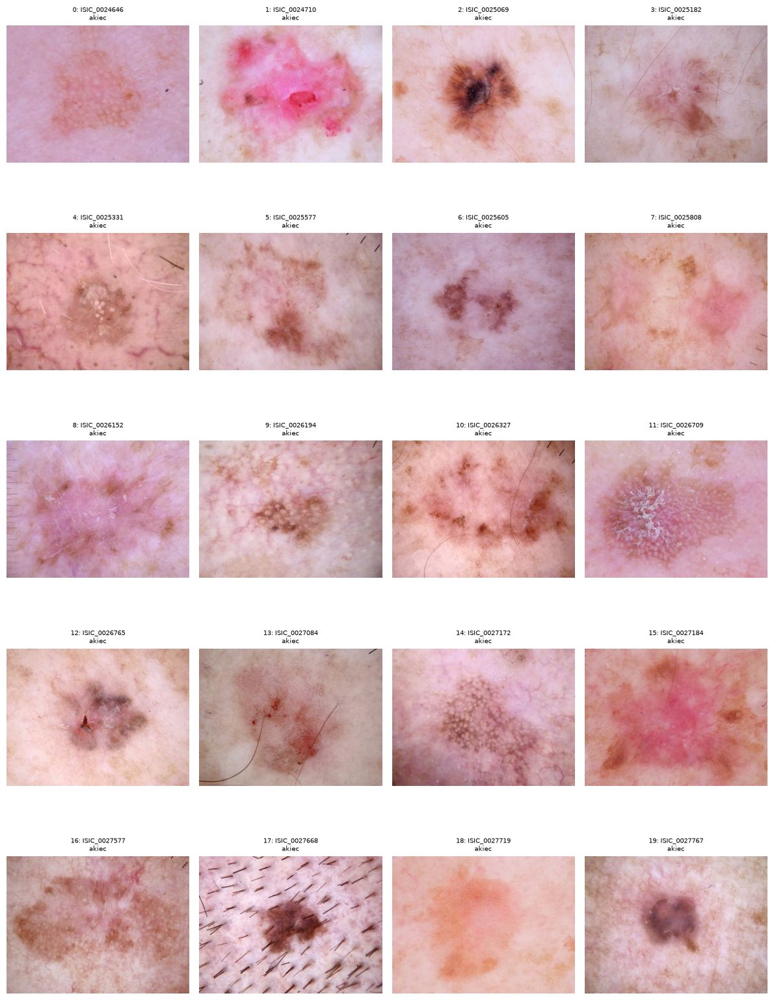

In [8]:
pagina = 0
tam = cfg["eda_annotation_page_size"]
n_paginas = int(np.ceil(len(anot) / tam))
sub = anot.iloc[pagina * tam:(pagina + 1) * tam]
display(pd.Series({"página": f"{pagina + 1} de {n_paginas}"}, name="valor").to_frame())
eda.plot_image_grid(sub["image_id"].map(cache),
                    sub.index.to_series().astype(str) + ": " + sub["image_id"] + "\n" + sub["dx"],
                    ncols=cfg["eda_grid_ncols"] // 2, cell_size=3)
plt.show()

### Criterios de anotación de artefactos

La anotación se realizó sobre una muestra estratificada de 40 imágenes por clase
(280 en total), registrando la presencia (1) o ausencia (0) de seis artefactos de
adquisición. Los criterios se definieron de forma operativa para este trabajo:

| Artefacto | Se marca 1 si… |
|---|---|
| Regla | Se observa al menos un tramo de escala graduada o marcas cortas de escala en el borde o en una esquina de la imagen |
| Tinta | Aparece cualquier trazo de marcador sobre la piel |
| Vello | Hay al menos dos o tres pelos claramente visibles; un pelo aislado no se cuenta |
| Burbujas | Hay al menos una burbuja de aire o de gel claramente visible |
| Viñeteado | Al menos una esquina está claramente oscurecida, o la imagen presenta un marco circular oscuro |
| Parche de color | Se observa un parche de calibración de color, aunque sea parcialmente |

En los casos dudosos se asignó 0, de modo que cada valor positivo corresponde a un
artefacto claramente identificable.

La anotación fue realizada por un asistente de inteligencia artificial, que evaluó
las imágenes identificadas únicamente por un número de orden aleatorio, sin acceso
a la clase diagnóstica. El autor revisó visualmente las 91 imágenes anotadas sin
ningún artefacto, sin encontrar casos que contradijeran los criterios. No se estimó
formalmente el acuerdo entre anotadores, por lo que la fiabilidad de la anotación
constituye una limitación de este análisis.

### 4.2 Prevalencia de artefactos por clase

Solo si todas las filas tienen las columnas de artefacto en 0 o 1. Chi-cuadrado y V de
Cramér de cada artefacto frente a `dx`.

In [9]:
estado = eda.annotation_status(anot, cols_art)
display(pd.Series(estado, name="valor").to_frame())
if estado["completo"]:
    display(eda.artifact_prevalence(anot, cols_art).loc[orden_dx].round(1))
    display(stats.chi2_table(anot.assign(**{c: pd.to_numeric(anot[c]) for c in cols_art}), cols_art, "dx",
                             n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"]))
else:
    aviso = (f"{ruta_anot} no está anotado por completo "
             f"({estado['n_completas']} de {estado['n_filas']} filas). Se omite el análisis.")
    display(pd.DataFrame({"aviso": [aviso]}))

,valor
n_filas,280
n_completas,280
n_celdas_no_validas,0
completo,True


,regla,tinta,vello,burbujas,vineteado,parche_color
dx,,,,,,
nv,5.0,0.0,52.5,5.0,5.0,0.0
mel,27.5,0.0,40.0,10.0,25.0,0.0
bkl,35.0,2.5,27.5,17.5,25.0,0.0
bcc,15.0,2.5,40.0,7.5,17.5,0.0
akiec,37.5,0.0,40.0,12.5,2.5,0.0
vasc,5.0,0.0,35.0,5.0,10.0,0.0
df,25.0,0.0,72.5,10.0,17.5,0.0


,chi2,gl,p_asintotico,p_simulado,v_cramer,n,prop_esperadas_lt5,iteraciones_mc
regla,25.496970,6.0,0.000276,0.000800,0.301762,280.0,0.0,10000.0
tinta,5.035971,6.0,0.539208,1.000000,0.134110,280.0,0.5,10000.0
vello,20.879292,6.0,0.001929,0.001900,0.273073,280.0,0.0,10000.0
burbujas,5.410628,6.0,0.492324,0.527347,0.139010,280.0,0.5,10000.0
vineteado,15.773038,6.0,0.015025,0.014799,0.237344,280.0,0.0,10000.0
parche_color,NaN,0.0,NaN,NaN,NaN,280.0,NaN,10000.0


### 4.3 Indicador automático de viñeteado

Con las máscaras de segmentación, sobre la caché. `lum_esquinas`: luminancia media de las
cuatro esquinas (cuadrados de lado `eda_vignette_corner_frac` × lado menor) sin píxeles de
lesión. `indice_vineteado`: `lum_esquinas` dividida por la mediana de la luminancia del
fondo de piel (píxeles que no son lesión ni esquina).

In [10]:
vin = eda.vignetting_table(train["image_id"], train["cache_path"], data.mask_paths(cfg, train["image_id"]),
                           cfg["eda_vignette_corner_frac"], cfg["mask_threshold"], cfg["eda_luma_weights"])
vin = vin.merge(train[["image_id", "dx"]], on="image_id")
vars_vin = ["lum_esquinas", "indice_vineteado"]
titulos_vin = {"lum_esquinas": "Luminancia media de las esquinas (sin lesión)",
               "indice_vineteado": "Índice de viñeteado (esquinas / mediana de la piel)"}
pd.Series({"imágenes sin valor del índice": int(vin["indice_vineteado"].isna().sum())}, name="valor").to_frame()

Viñeteado: 100%|██████████| 8584/8584 [00:11<00:00, 734.11it/s]


,valor
imágenes sin valor del índice,3


Distribución de cada indicador.

In [11]:
stats.univariate_summary(vin, vars_vin)

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
lum_esquinas,3,8581.0,0.588902,0.159327,0.000631,0.536908,0.624429,0.687231,0.971528,-1.553976
indice_vineteado,3,8581.0,0.870766,0.202746,0.001084,0.847385,0.952480,0.981009,1.174604,-2.518004


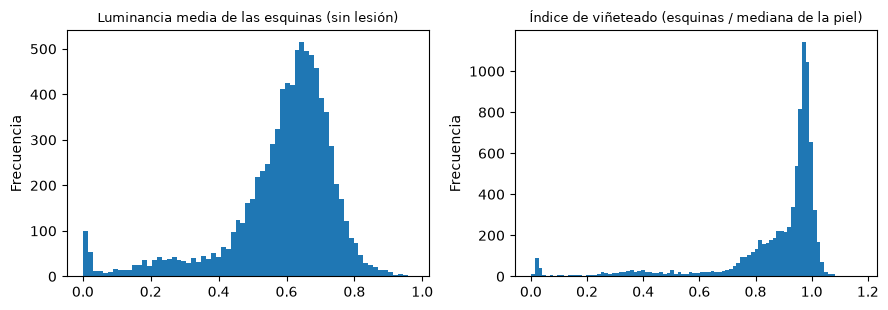

In [12]:
eda.plot_histograms(vin, vars_vin, cfg["eda_hist_bins"], ncols=2, titles=titulos_vin)
plt.show()

Por clase, con Kruskal-Wallis y ε².

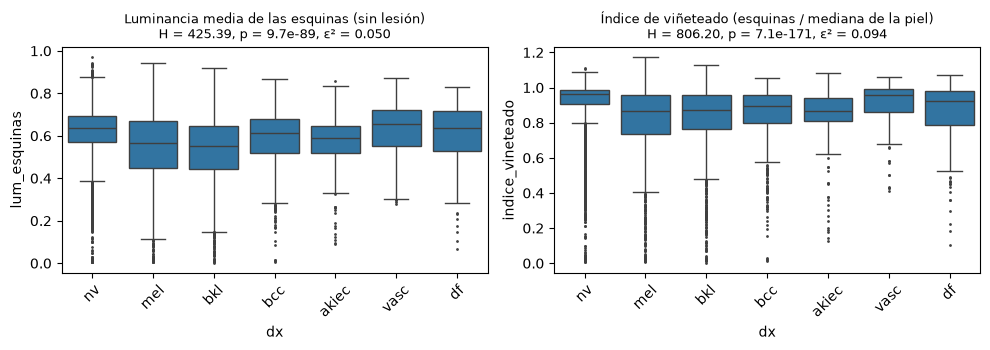

,H,gl,p,epsilon2,n,k
lum_esquinas,425.391477,6.0,9.682457e-89,0.049579,8581.0,7.0
indice_vineteado,806.196692,6.0,7.056016e-171,0.093962,8581.0,7.0


In [13]:
kw_vin = stats.kruskal_table(vin, vars_vin, "dx")
eda.boxplot_grid(vin, vars_vin, "dx", order=orden_dx, tests=kw_vin, ncols=2, titles=titulos_vin)
plt.show()
kw_vin

In [14]:
vin.groupby("dx")["indice_vineteado"].describe().loc[orden_dx]

,count,mean,std,min,25%,50%,75%,max
dx,,,,,,,,
nv,5747.0,0.903391,0.176863,0.006946,0.908964,0.964951,0.984419,1.110066
mel,953.0,0.774264,0.267545,0.009803,0.736577,0.865503,0.958860,1.174604
bkl,941.0,0.797507,0.233896,0.001084,0.764362,0.870674,0.956201,1.131090
bcc,440.0,0.829665,0.199205,0.012171,0.799284,0.895231,0.958838,1.055096
akiec,280.0,0.840770,0.158458,0.124564,0.810678,0.864427,0.937960,1.082044
vasc,122.0,0.902368,0.145821,0.411891,0.863030,0.959875,0.990931,1.062909
df,98.0,0.830350,0.228493,0.106762,0.788726,0.925454,0.982889,1.072291


In [15]:
vin.groupby("dx")["lum_esquinas"].describe().loc[orden_dx]

,count,mean,std,min,25%,50%,75%,max
dx,,,,,,,,
nv,5747.0,0.611182,0.141138,0.003458,0.569485,0.638592,0.692679,0.971528
mel,953.0,0.528186,0.205553,0.005224,0.447513,0.566899,0.671428,0.944333
bkl,941.0,0.520711,0.181654,0.000631,0.445517,0.551611,0.644479,0.918483
bcc,440.0,0.574900,0.157755,0.006052,0.517480,0.611957,0.678148,0.869187
akiec,280.0,0.572650,0.130025,0.090453,0.518772,0.589124,0.646954,0.856125
vasc,122.0,0.629646,0.134351,0.280694,0.553245,0.655399,0.721307,0.872167
df,98.0,0.586128,0.180781,0.065002,0.527139,0.634474,0.716761,0.829088


## 5. Dimensiones y formato

Ancho, alto, relación de aspecto, modo de color y tamaño de archivo de las imágenes
originales, por clase.

In [16]:
info = eda.file_info_table(train["image_id"], rutas_orig).merge(train[["image_id", "dx"]], on="image_id")
info["resolucion"] = info["ancho"].astype(str) + "x" + info["alto"].astype(str)
info.head()

Dimensiones: 100%|██████████| 8584/8584 [00:00<00:00, 19395.63it/s]


,image_id,ancho,alto,relacion_aspecto,modo,formato,tamano_kb,dx,resolucion
0,ISIC_0027419,600,450,1.333333,RGB,JPEG,304.610352,bkl,600x450
1,ISIC_0025030,600,450,1.333333,RGB,JPEG,311.632812,bkl,600x450
2,ISIC_0026769,600,450,1.333333,RGB,JPEG,294.756836,bkl,600x450
3,ISIC_0025661,600,450,1.333333,RGB,JPEG,337.428711,bkl,600x450
4,ISIC_0031633,600,450,1.333333,RGB,JPEG,250.268555,bkl,600x450


In [17]:
pd.crosstab(info["dx"], info["resolucion"], margins=True, margins_name="Total")

resolucion,600x450,Total
dx,,
akiec,281,281
bcc,440,440
bkl,942,942
df,98,98
mel,954,954
nv,5747,5747
vasc,122,122
Total,8584,8584


In [18]:
pd.crosstab(info["dx"], [info["formato"], info["modo"]], margins=True, margins_name="Total")

formato,JPEG,Total
modo,RGB,
dx,,
akiec,281,281
bcc,440,440
bkl,942,942
df,98,98
mel,954,954
nv,5747,5747
vasc,122,122
Total,8584,8584


In [19]:
info.groupby("dx")[["ancho", "alto", "relacion_aspecto", "tamano_kb"]].agg(["min", "median", "max"]).loc[orden_dx]

ancho             alto             relacion_aspecto                      \
        min median  max  min median  max              min    median       max   
dx                                                                              
nv      600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
mel     600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
bkl     600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
bcc     600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
akiec   600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
vasc    600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   
df      600  600.0  600  450  450.0  450         1.333333  1.333333  1.333333   

        tamano_kb                          
              min      median         max  
dx                                         
nv      83.332031  269.440430  418.776367  
mel    122.078125  288.088867  479.273438  
bkl    121.448242  274.718262  404.376953  
bcc    106.122070  253.080078  448.410156  
akiec  133.724609  256.722656  360.993164  
vasc   157.337891  271.240723  410.137695  
df     134.268555  291.726074  370.289062

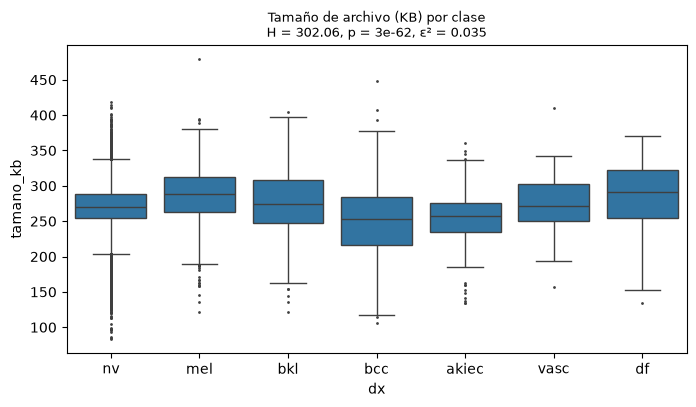

In [20]:
res_kb = stats.kruskal_epsilon2(info["tamano_kb"], info["dx"])
eda.boxplot_by_class(info, "tamano_kb", "dx", order=orden_dx, title="Tamaño de archivo (KB) por clase",
                     test=res_kb)
plt.show()

### Profundidad de bits y nitidez

Una sola pasada sobre las imágenes originales calcula, por imagen: bits por canal según el
modo de PIL (`bits_modo`) y según el dtype del arreglo (`bits_dtype`); nitidez como
varianza del laplaciano de la luminancia (escala 0–255); y, para la sección 6.4, el
porcentaje de píxeles recortados por canal y los histogramas de intensidad de 256 niveles
por canal, para todo train y por clase.

In [21]:
calidad, hist_int = eda.pixel_quality_pass(train["image_id"], rutas_orig, train["dx"], cfg["eda_luma_weights"],
                                           cfg["clip_low"], cfg["clip_high"])
calidad = calidad.merge(train[["image_id", "dx"]], on="image_id")

Calidad de imagen: 100%|██████████| 8584/8584 [01:49<00:00, 78.34it/s]


Frecuencia de la profundidad de bits.

In [22]:
calidad.value_counts(["modo", "bits_modo", "dtype", "bits_dtype"]).rename("imágenes").to_frame()

,,,,imágenes
modo,bits_modo,dtype,bits_dtype,
RGB,8,uint8,8,8584


Nitidez (varianza del laplaciano): descriptivos y por clase, con Kruskal-Wallis y ε².

In [23]:
stats.univariate_summary(calidad, ["nitidez"])

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
nitidez,0,8584.0,79.707545,125.011818,7.903472,34.957813,49.5238,89.684675,3814.566514,14.500582


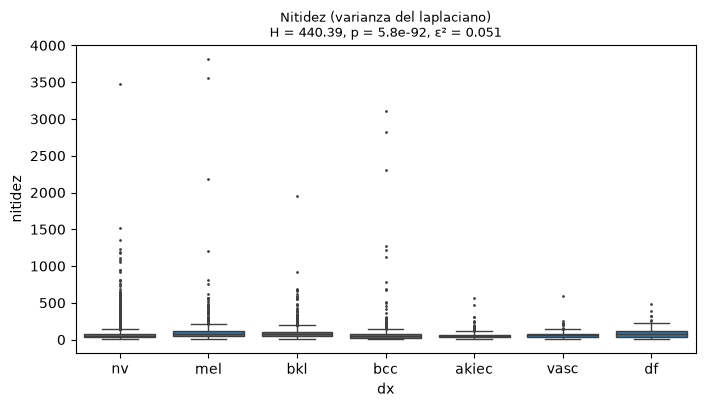

,nitidez
H,4.403852e+02
gl,6.000000e+00
p,5.755447e-92
epsilon2,5.130901e-02
n,8.584000e+03
k,7.000000e+00


In [24]:
res_nit = stats.kruskal_epsilon2(calidad["nitidez"], calidad["dx"])
eda.boxplot_by_class(calidad, "nitidez", "dx", order=orden_dx, title="Nitidez (varianza del laplaciano)",
                     test=res_nit)
plt.show()
pd.Series(res_nit, name="nitidez").to_frame()

## 6. Color

### 6.1 Estadísticas globales por canal

Media y desviación estándar de R, G y B sobre todos los píxeles de las imágenes
originales de entrenamiento. Se guardan en `data/train_color_stats.json`. En la misma
pasada se calculan las características por imagen de 6.2.

In [25]:
color_img, color_global = eda.color_features(train["image_id"], rutas_orig, cfg["eda_luma_weights"])
data.save_json(color_global, rutas["train_color_stats_json"])
color_global

Color: 100%|██████████| 8584/8584 [03:42<00:00, 38.62it/s]


{'escala': '[0, 1]',
 'canales': ['R', 'G', 'B'],
 'media': [0.7633448709457645, 0.5459043764893733, 0.5702200201908665],
 'std': [0.14142908930950454, 0.15309897687857643, 0.17048982974291169],
 'media_255': [194.65294209116996, 139.2056160047902, 145.40610514867095],
 'std_255': [36.06441777392366, 39.04023910403699, 43.47490658444248],
 'n_imagenes': 8584,
 'n_pixeles': 2317680000}

### 6.2 Color por imagen

Media de cada canal, luminancia, contraste (desviación de la luminancia) y saturación
(canal S de HSV), por clase, con Kruskal-Wallis y ε².

Distribución de cada variable.

In [26]:
vars_color = ["media_r", "media_g", "media_b", "luminancia", "contraste", "saturacion"]
stats.univariate_summary(color_img, vars_color)

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
media_r,0,8584.0,0.763345,0.098518,0.247249,0.692525,0.772047,0.838496,0.997208,-0.325116
media_g,0,8584.0,0.545904,0.085916,0.204021,0.489529,0.545566,0.601725,0.878556,0.045265
media_b,0,8584.0,0.570220,0.095435,0.217506,0.507764,0.569187,0.632875,0.934141,0.074244
luminancia,0,8584.0,0.613691,0.075616,0.228281,0.562869,0.613090,0.664054,0.901513,0.012102
contraste,0,8584.0,0.109940,0.044752,0.020730,0.077494,0.102157,0.134094,0.335221,0.961402
saturacion,0,8584.0,0.304894,0.118094,0.033930,0.206217,0.290182,0.402863,0.710100,0.226673


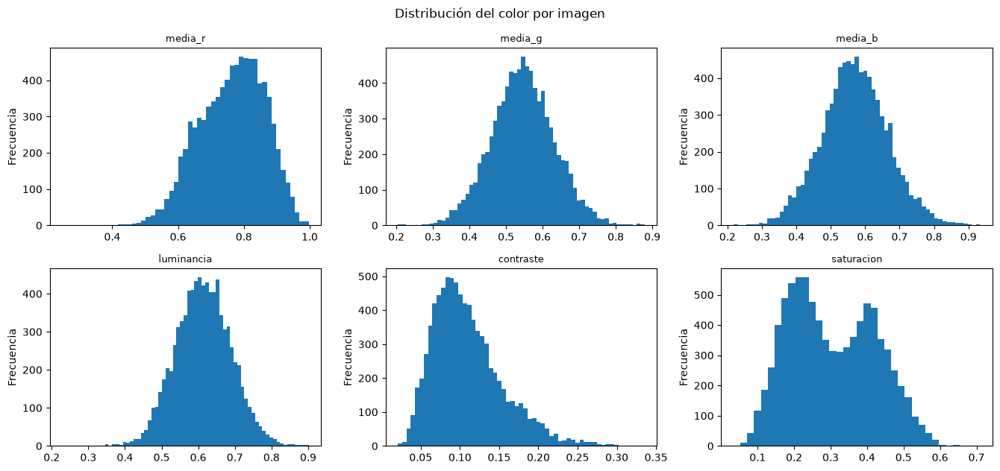

In [27]:
eda.plot_histograms(color_img, vars_color, cfg["eda_hist_bins"], suptitle="Distribución del color por imagen")
plt.show()

Por clase.

In [28]:
vars_color = ["media_r", "media_g", "media_b", "luminancia", "contraste", "saturacion"]
cols_extra = [fuente] if tiene_fuente else []
color = color_img.merge(train[["image_id", "dx", *cols_extra]], on="image_id")
kw_color = stats.kruskal_table(color, vars_color, "dx")
kw_color

,H,gl,p,epsilon2,n,k
media_r,1073.373719,6.0,1.201957e-228,0.125058,8584.0,7.0
media_g,430.220410,6.0,8.854310e-90,0.050125,8584.0,7.0
media_b,430.175077,6.0,9.055399e-90,0.050119,8584.0,7.0
luminancia,412.722729,6.0,5.138470e-86,0.048086,8584.0,7.0
contraste,579.866316,6.0,5.130870e-122,0.067560,8584.0,7.0
saturacion,984.746145,6.0,1.779977e-209,0.114732,8584.0,7.0


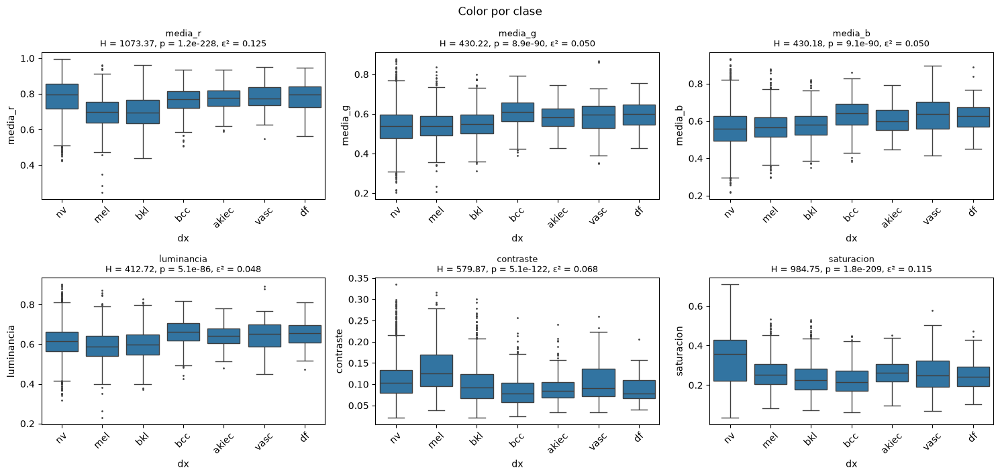

In [29]:
eda.boxplot_grid(color, vars_color, "dx", order=orden_dx, tests=kw_color, suptitle="Color por clase")
plt.show()

Las mismas variables por fuente, si existe la columna `source_column`.

,H,gl,p,epsilon2,n,k
media_r,3609.267243,3.0,0.000000e+00,0.420513,8584.0,4.0
media_g,1465.776912,3.0,0.000000e+00,0.170777,8584.0,4.0
media_b,1648.304158,3.0,0.000000e+00,0.192043,8584.0,4.0
luminancia,265.835954,3.0,2.456561e-57,0.030972,8584.0,4.0
contraste,685.965286,3.0,2.318749e-148,0.079921,8584.0,4.0
saturacion,5740.249998,3.0,0.000000e+00,0.668793,8584.0,4.0


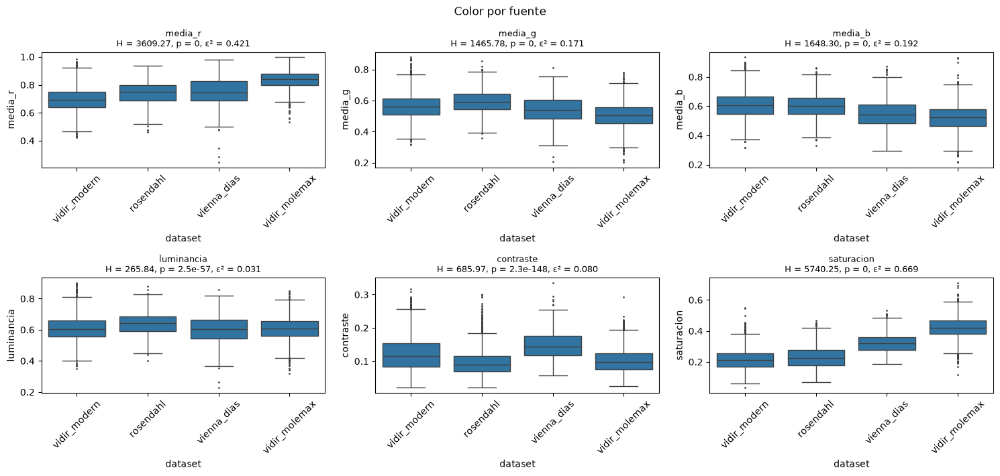

In [30]:
if tiene_fuente:
    kw_fuente = stats.kruskal_table(color, vars_color, fuente)
    display(kw_fuente)
    eda.boxplot_grid(color, vars_color, fuente, tests=kw_fuente, suptitle="Color por fuente")
    plt.show()
else:
    display(pd.DataFrame({"aviso": [f"No existe la columna '{fuente}'."]}))

### 6.3 Shades of Gray

Constancia de color Shades of Gray con p = `shades_of_gray_p` aplicada a
`eda_sog_examples_per_class` imágenes por clase. Solo visualización: no se modifica
ningún archivo.

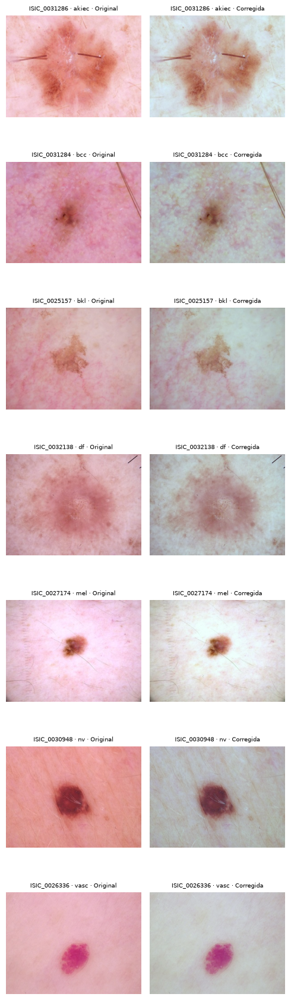

In [31]:
ejemplos = eda.sample_per_class(train, cfg["eda_sog_examples_per_class"], cfg["seed"])
eda.plot_before_after(ejemplos["cache_path"],
                      lambda im: eda.shades_of_gray(im, cfg["shades_of_gray_p"]),
                      ejemplos["image_id"] + " · " + ejemplos["dx"])
plt.show()

### 6.4 Histogramas de intensidad y píxeles recortados

Histogramas de intensidad por canal a nivel de píxel (256 niveles) acumulados sobre todo
train y, por clase, superpuestos y normalizados. Porcentaje de píxeles recortados por
canal (valor <= `clip_low` o >= `clip_high`) por imagen.

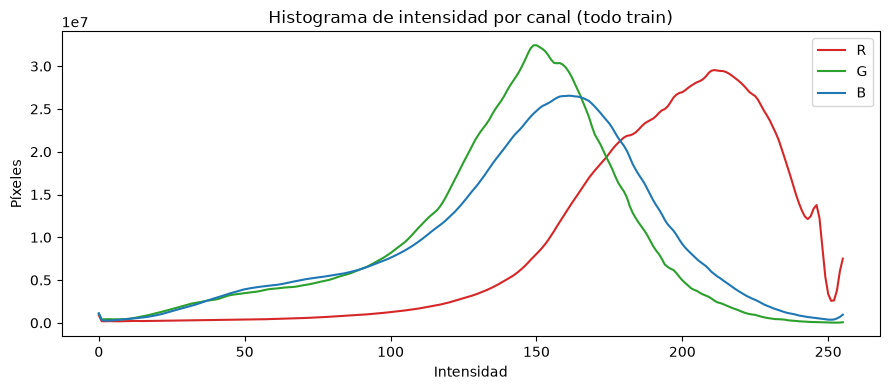

In [32]:
eda.plot_channel_histograms(hist_int["Todo"], "Histograma de intensidad por canal (todo train)")
plt.show()

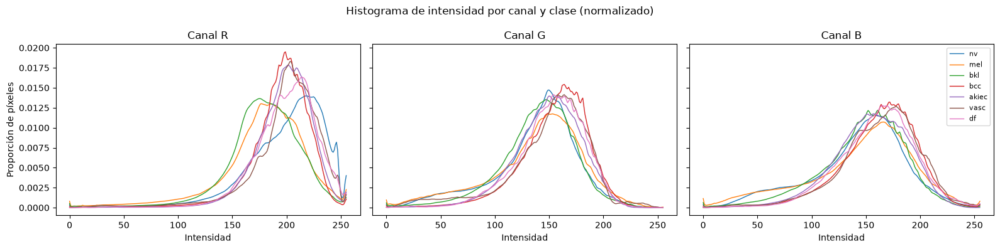

In [33]:
eda.plot_class_channel_histograms(hist_int, orden_dx, "Histograma de intensidad por canal y clase (normalizado)")
plt.show()

Porcentaje de píxeles recortados por canal: descriptivos.

In [34]:
vars_rec = ["recorte_r", "recorte_g", "recorte_b"]
stats.univariate_summary(calidad, vars_rec)

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
recorte_r,0,8584.0,0.361885,2.692706,0.0,0.0,0.0,0.000370,50.647778,11.310562
recorte_g,0,8584.0,0.049607,0.341175,0.0,0.0,0.0,0.000000,11.896296,15.853750
recorte_b,0,8584.0,0.089029,0.741129,0.0,0.0,0.0,0.000741,29.181481,19.547729


Por clase, con Kruskal-Wallis y ε².

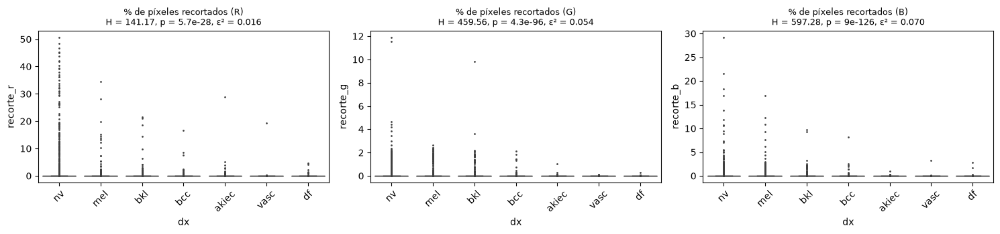

,H,gl,p,epsilon2,n,k
recorte_r,141.165857,6.0,5.687184e-28,0.016447,8584.0,7.0
recorte_g,459.560768,6.0,4.295593e-96,0.053543,8584.0,7.0
recorte_b,597.284412,6.0,8.985015e-126,0.069589,8584.0,7.0


In [35]:
kw_rec = stats.kruskal_table(calidad, vars_rec, "dx")
eda.boxplot_grid(calidad, vars_rec, "dx", order=orden_dx, tests=kw_rec,
                 titles={"recorte_r": "% de píxeles recortados (R)", "recorte_g": "% de píxeles recortados (G)",
                         "recorte_b": "% de píxeles recortados (B)"})
plt.show()
kw_rec

Imágenes con más de `clip_frac_alert` de píxeles recortados en algún canal, en total y por clase.

In [36]:
calidad["alerta_recorte"] = eda.clip_alert(calidad, vars_rec, cfg["clip_frac_alert"])
eda.flag_table(calidad, "alerta_recorte", "dx", orden_dx)

,imagenes,marcadas,pct_marcadas
dx,,,
nv,5747,304,5.289716
mel,954,76,7.966457
bkl,942,41,4.352442
bcc,440,14,3.181818
akiec,281,9,3.202847
vasc,122,1,0.819672
df,98,8,8.163265
Total,8584,453,5.277260


## 7. Tamaño y posición de la lesión

Con las máscaras de segmentación: fracción del área de la imagen ocupada por la lesión,
distancia del centroide al centro (normalizada por la semidiagonal) y si la lesión toca
el borde. 7.1 es el control de calidad de las máscaras, 7.2 la distribución de cada
variable y 7.3 los análisis por clase: Kruskal-Wallis para las variables continuas y
chi-cuadrado (p-valor asintótico y simulado) con V de Cramér para la variable binaria.

In [37]:
les = eda.lesion_features_table(train["image_id"], rutas_orig, data.mask_paths(cfg, train["image_id"]),
                                cfg["mask_threshold"], cfg["eda_luma_weights"])
les = les.merge(train[["image_id", "dx"]], on="image_id")
pd.Series({"imágenes sin máscara": int((~les["mascara_existe"]).sum())}, name="valor").to_frame()

Máscaras: 100%|██████████| 8584/8584 [02:24<00:00, 59.54it/s]


,valor
imágenes sin máscara,0


### 7.1 Control de calidad de las máscaras

Distribución de la fracción de área de las máscaras; conteo, global y por clase, de
máscaras casi vacías (fracción < `mask_min_frac`) y casi completas (fracción >
`mask_max_frac`); contornos de las máscaras sobre las imágenes de la caché.

In [38]:
stats.univariate_summary(les, ["fraccion_area"])

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
fraccion_area,0,8584.0,0.266361,0.188325,0.003856,0.119668,0.222861,0.375669,1.0,0.997456


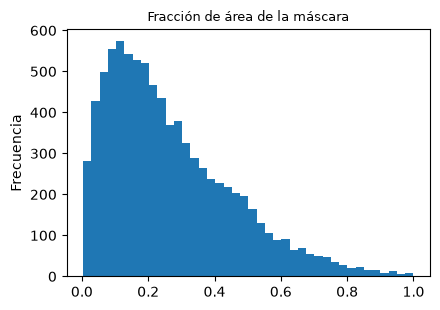

In [39]:
eda.plot_histograms(les, ["fraccion_area"], cfg["eda_hist_bins"],
                    titles={"fraccion_area": "Fracción de área de la máscara"})
plt.show()

In [40]:
qc = eda.mask_qc_flags(les[les["mascara_existe"]], cfg["mask_min_frac"], cfg["mask_max_frac"])
eda.mask_qc_table(qc, orden_dx)

,n,casi_vacia,casi_completa
dx,,,
nv,5747,0,8
mel,954,0,2
bkl,942,0,1
bcc,440,0,0
akiec,281,0,3
vasc,122,0,0
df,98,0,0
Total,8584,0,14


`eda_mask_overlay_n` imágenes aleatorias (semilla fija) con el contorno de la máscara.

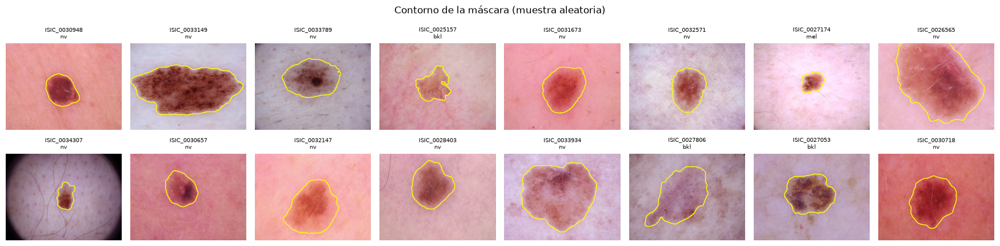

In [41]:
n_over = cfg["eda_mask_overlay_n"]
azar = train[train["image_id"].isin(qc["image_id"])].sample(min(n_over, len(qc)), random_state=cfg["seed"])
eda.plot_mask_overlays(azar["cache_path"], data.mask_paths(cfg, azar["image_id"]),
                       azar["image_id"] + "\n" + azar["dx"], ncols=cfg["eda_grid_ncols"],
                       mask_threshold=cfg["mask_threshold"], suptitle="Contorno de la máscara (muestra aleatoria)")
plt.show()

Máscaras marcadas como casi vacías o casi completas (como máximo `eda_mask_overlay_n`, elegidas al azar con semilla fija).

,valor
máscaras marcadas,14


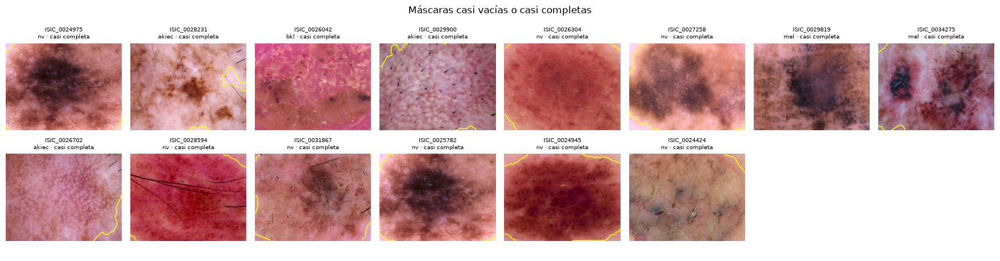

In [42]:
marcadas = qc[qc["casi_vacia"] | qc["casi_completa"]]
display(pd.Series({"máscaras marcadas": len(marcadas)}, name="valor").to_frame())
if len(marcadas):
    sel = marcadas.sample(min(n_over, len(marcadas)), random_state=cfg["seed"])
    marca = np.where(sel["casi_vacia"], "casi vacía", "casi completa")
    eda.plot_mask_overlays(sel["image_id"].map(cache), data.mask_paths(cfg, sel["image_id"]),
                           sel["image_id"] + "\n" + sel["dx"] + " · " + marca, ncols=cfg["eda_grid_ncols"],
                           mask_threshold=cfg["mask_threshold"], suptitle="Máscaras casi vacías o casi completas")
    plt.show()

### 7.2 Distribución de cada variable

Distancia del centroide, luminancia de la lesión y del fondo, diferencia de luminancia
lesión − fondo y contacto con el borde. La fracción de área está en 7.1.

In [43]:
les["dif_luminancia"] = les["lesion_luminancia"] - les["fondo_luminancia"]
vars_les_uni = ["dist_centroide", "lesion_luminancia", "fondo_luminancia", "dif_luminancia"]
stats.univariate_summary(les, vars_les_uni)

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
dist_centroide,0,8584.0,0.089201,0.067808,0.000000,0.040546,0.070282,0.119769,0.506395,1.544526
lesion_luminancia,0,8584.0,0.474119,0.102151,0.134669,0.403110,0.473631,0.545120,0.833888,-0.045570
fondo_luminancia,2,8582.0,0.661255,0.082798,0.153365,0.608802,0.662487,0.714331,0.979632,-0.061417
dif_luminancia,2,8582.0,-0.187127,0.114166,-0.648850,-0.258255,-0.185821,-0.111423,0.457471,-0.092142


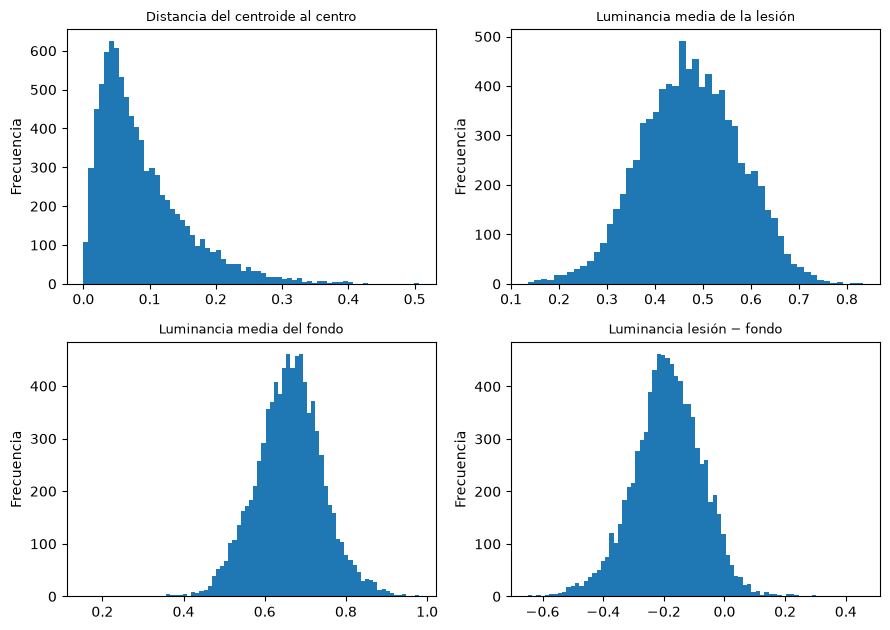

In [44]:
eda.plot_histograms(les, vars_les_uni, cfg["eda_hist_bins"], ncols=2,
                    titles={"dist_centroide": "Distancia del centroide al centro",
                            "lesion_luminancia": "Luminancia media de la lesión",
                            "fondo_luminancia": "Luminancia media del fondo",
                            "dif_luminancia": "Luminancia lesión − fondo"})
plt.show()

In [45]:
stats.value_counts_pct(les["toca_borde"].dropna().astype(bool)).rename_axis("toca_borde")

,n,porcentaje
toca_borde,,
False,7221,84.121622
True,1363,15.878378


### 7.3 Por clase

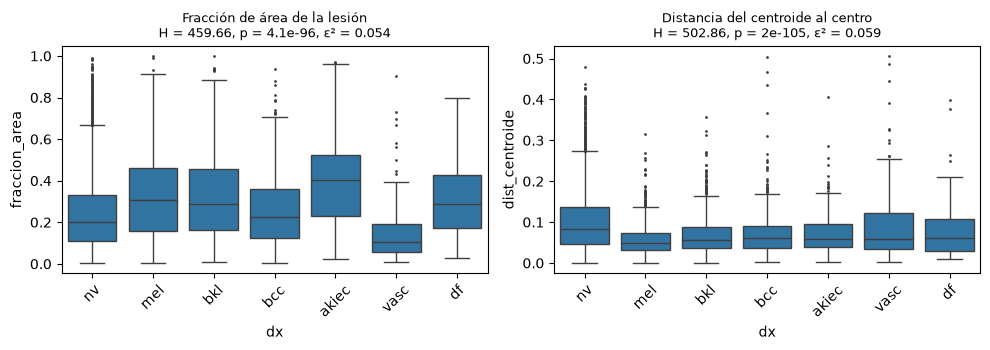

,H,gl,p,epsilon2,n,k
fraccion_area,459.659128,6.0,4.091189e-96,0.053555,8584.0,7.0
dist_centroide,502.861608,6.0,2.033531e-105,0.058588,8584.0,7.0


In [46]:
vars_les = ["fraccion_area", "dist_centroide"]
kw_les = stats.kruskal_table(les, vars_les, "dx")
eda.boxplot_grid(les, vars_les, "dx", order=orden_dx, tests=kw_les, ncols=2,
                 titles={"fraccion_area": "Fracción de área de la lesión",
                         "dist_centroide": "Distancia del centroide al centro"})
plt.show()
kw_les

In [47]:
toca = les.dropna(subset=["toca_borde"]).astype({"toca_borde": bool})
display((toca.groupby("dx")["toca_borde"].mean() * 100).loc[orden_dx].rename("% toca el borde").to_frame())
pd.Series(stats.chi2_from_columns(toca, "toca_borde", "dx", n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"]), name="toca_borde").to_frame()

,% toca el borde
dx,
nv,14.233513
mel,19.496855
bkl,20.063694
bcc,11.818182
akiec,34.519573
vasc,5.737705
df,14.285714


,toca_borde
chi2,1.214589e+02
gl,6.000000e+00
p_asintotico,8.046258e-24
p_simulado,9.999000e-05
v_cramer,1.189515e-01
n,8.584000e+03
prop_esperadas_lt5,0.000000e+00
iteraciones_mc,1.000000e+04


Color medio (RGB en [0, 1] y luminancia) dentro de la lesión y en el fondo, por clase, y
diferencia de luminancia lesión − fondo.

In [48]:
cols_rgb = [f"{r}_{c}" for r in ("lesion", "fondo") for c in ("r", "g", "b", "luminancia")]
les.groupby("dx")[cols_rgb].mean().loc[orden_dx].round(3)

,lesion_r,lesion_g,lesion_b,lesion_luminancia,fondo_r,fondo_g,fondo_b,fondo_luminancia
dx,,,,,,,,
nv,0.670,0.360,0.355,0.452,0.819,0.595,0.626,0.666
mel,0.605,0.390,0.388,0.454,0.741,0.610,0.649,0.654
bkl,0.655,0.463,0.467,0.521,0.719,0.583,0.624,0.628
bcc,0.743,0.541,0.575,0.605,0.771,0.631,0.654,0.675
akiec,0.762,0.534,0.550,0.604,0.781,0.613,0.636,0.665
vasc,0.639,0.330,0.461,0.438,0.811,0.627,0.668,0.687
df,0.761,0.516,0.547,0.593,0.796,0.636,0.667,0.687


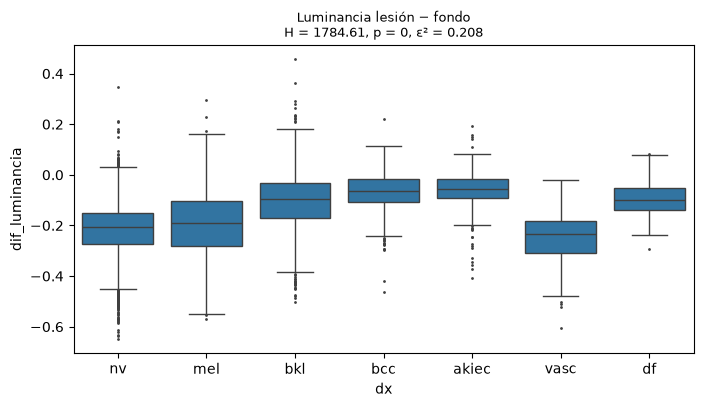

In [49]:
les["dif_luminancia"] = les["lesion_luminancia"] - les["fondo_luminancia"]
res_dif = stats.kruskal_epsilon2(les["dif_luminancia"], les["dx"])
eda.boxplot_by_class(les, "dif_luminancia", "dx", order=orden_dx,
                     title="Luminancia lesión − fondo", test=res_dif)
plt.show()

## 8. Mapas medios de máscaras y capacidad predictiva del fondo

### 8.1 Mapa medio de máscaras

Cada máscara se binariza, se redimensiona a `eda_mean_image_size` por promedio de área y
se promedia: para todo train, por clase y por fuente. Escala común de 0 a 1.

In [50]:
con_mascara = train[train["image_id"].isin(les.loc[les["mascara_existe"], "image_id"])].reset_index(drop=True)
mascaras = eda.load_masks_resized(data.mask_paths(cfg, con_mascara["image_id"]),
                                  cfg["eda_mean_image_size"], cfg["mask_threshold"])
ncols_mapas = cfg["eda_grid_ncols"] // 2
pd.Series({"máscaras": mascaras.shape[0], "alto": mascaras.shape[1], "ancho": mascaras.shape[2]}, name="valor").to_frame()

Máscaras redimensionadas: 100%|██████████| 8584/8584 [00:03<00:00, 2328.77it/s]


,valor
máscaras,8584
alto,48
ancho,64


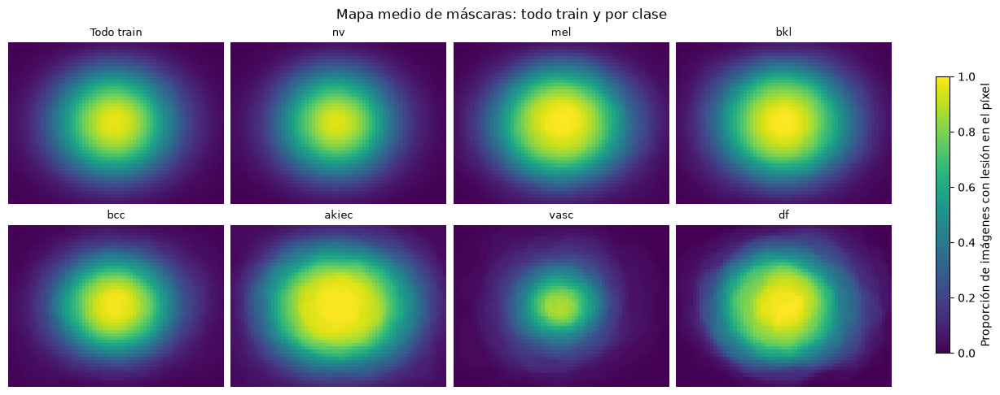

In [51]:
mapas = {"Todo train": mascaras.mean(axis=0), **eda.group_means(mascaras, con_mascara["dx"], orden_dx)}
eda.plot_maps(mapas, ncols_mapas, "viridis", 0, 1, "Proporción de imágenes con lesión en el píxel",
              suptitle="Mapa medio de máscaras: todo train y por clase")
plt.show()

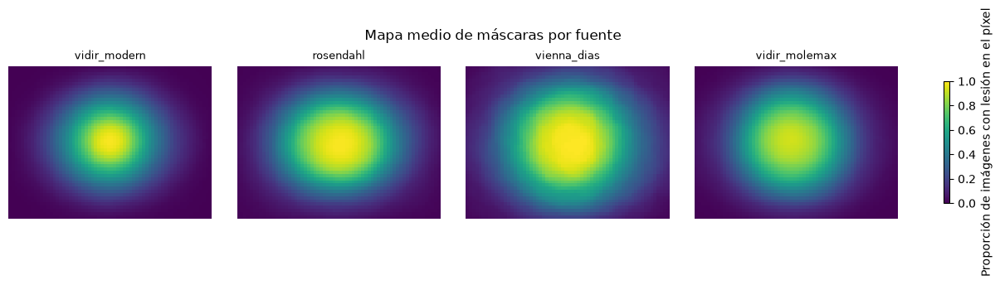

In [52]:
if tiene_fuente:
    mapas_fuente = eda.group_means(mascaras, con_mascara[fuente])
    eda.plot_maps(mapas_fuente, ncols_mapas, "viridis", 0, 1, "Proporción de imágenes con lesión en el píxel",
                  suptitle="Mapa medio de máscaras por fuente")
    plt.show()
else:
    display(pd.DataFrame({"aviso": [f"No existe la columna '{fuente}'."]}))

### 8.2 Capacidad predictiva de la lesión y del fondo

Por imagen (caché), histogramas de color normalizados de `adv_hist_bins` intervalos por
canal, calculados por separado con los píxeles de fondo (máscara = 0) y de lesión
(máscara = 1). Se excluyen las imágenes sin máscara, las imágenes cuyo fondo ocupa menos
de `min_background_frac` de la imagen y las imágenes sin píxeles de lesión. Regresión
logística multinomial (estandarización previa, `class_weight="balanced"`) con la columna
`fold` de `splits.csv` como pliegues, para fondo → dx, lesión → dx, fondo → fuente y
lesión → fuente.

In [53]:
reg = eda.region_color_histograms(train["cache_path"], data.mask_paths(cfg, train["image_id"]),
                                  cfg["adv_hist_bins"], cfg["mask_threshold"])
sin_mascara = np.isnan(reg["frac_fondo"])
poco_fondo = ~sin_mascara & (reg["frac_fondo"] < cfg["min_background_frac"])
sin_lesion = ~sin_mascara & (reg["frac_lesion"] == 0)
incluidas = ~(sin_mascara | poco_fondo | sin_lesion)
pd.Series({"sin máscara": int(sin_mascara.sum()),
           f"fondo < {cfg['min_background_frac']}": int(poco_fondo.sum()),
           "sin píxeles de lesión": int(sin_lesion.sum()),
           "incluidas": int(incluidas.sum()),
           "total train": len(train)}, name="imágenes").to_frame()

Histogramas por región: 100%|██████████| 8584/8584 [00:37<00:00, 227.37it/s]


,imágenes
sin máscara,0
fondo < 0.05,14
sin píxeles de lesión,0
incluidas,8570
total train,8584


In [54]:
sub_reg = train.loc[incluidas].reset_index(drop=True)
regiones = {"fondo": reg["fondo"][incluidas], "lesión": reg["lesion"][incluidas]}
objetivos = ["dx"] + ([fuente] if tiene_fuente else [])
resultados = {
    f"{region} -> {obj}": eda.fold_cv_classification(X, sub_reg[obj], sub_reg["fold"], cfg["bg_probe_max_iter"])
    for obj in objetivos for region, X in regiones.items()
}
cols_res = ["exactitud_balanceada_media", "exactitud_balanceada_std", "azar", "n", "n_clases"]
pd.DataFrame({k: {c: v[c] for c in cols_res} for k, v in resultados.items()}).T

,exactitud_balanceada_media,exactitud_balanceada_std,azar,n,n_clases
fondo -> dx,0.279170,0.008248,0.142857,8570.0,7.0
lesión -> dx,0.475893,0.022984,0.142857,8570.0,7.0
fondo -> dataset,0.701243,0.021961,0.250000,8570.0,4.0
lesión -> dataset,0.728146,0.010691,0.250000,8570.0,4.0


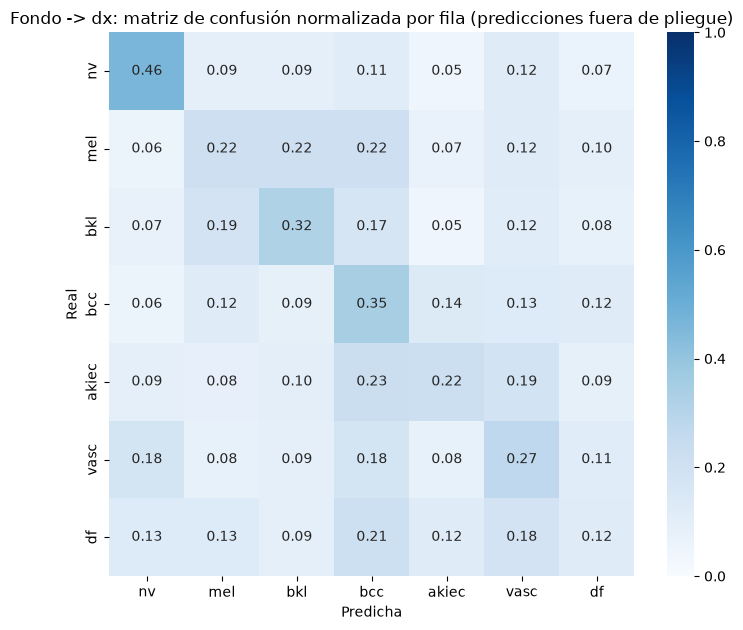

In [55]:
eda.plot_confusion(sub_reg["dx"], resultados["fondo -> dx"]["oof"], orden_dx,
                   "Fondo -> dx: matriz de confusión normalizada por fila (predicciones fuera de pliegue)")
plt.show()

## 9. Imágenes media y de desviación

Solo train (caché). Cada imagen se redimensiona a `eda_mean_image_size` por promedio de
área, con RGB en [0, 1]. Las medias se muestran en RGB; la desviación estándar y la
diferencia frente a la media de todo train, en luminancia. Las diferencias usan una
escala divergente centrada en 0 con un rango común para todas las clases y otro para
todas las fuentes.

In [56]:
agrupaciones = {"dx": train["dx"], **({fuente: train[fuente]} if tiene_fuente else {})}
img_stats = eda.mean_std_images(train["cache_path"], agrupaciones, cfg["eda_mean_image_size"],
                                cfg["eda_luma_weights"])
glob = img_stats["global"]["Todo"]

Imágenes media: 100%|██████████| 8584/8584 [00:04<00:00, 1882.10it/s]


### 9.1 Todo train

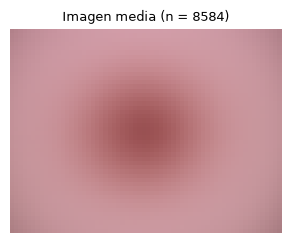

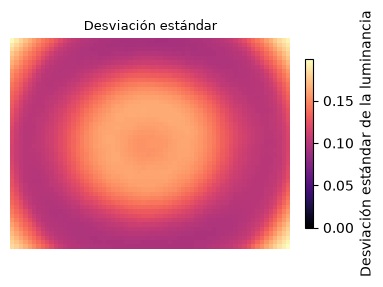

In [57]:
eda.plot_rgb_grid({f"Imagen media (n = {glob['n']})": glob["media_rgb"]}, 1)
plt.show()
eda.plot_maps({"Desviación estándar": glob["std_lum"]}, 1, "magma", 0, float(glob["std_lum"].max()),
              "Desviación estándar de la luminancia")
plt.show()

### 9.2 Por clase

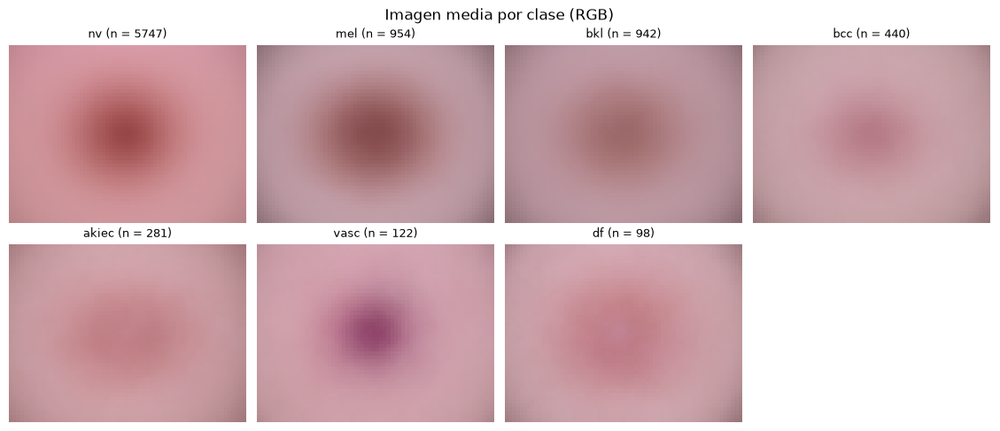

In [58]:
por_dx = {k: img_stats["dx"][k] for k in orden_dx}
eda.plot_rgb_grid({f"{k} (n = {v['n']})": v["media_rgb"] for k, v in por_dx.items()}, ncols_mapas,
                  suptitle="Imagen media por clase (RGB)")
plt.show()

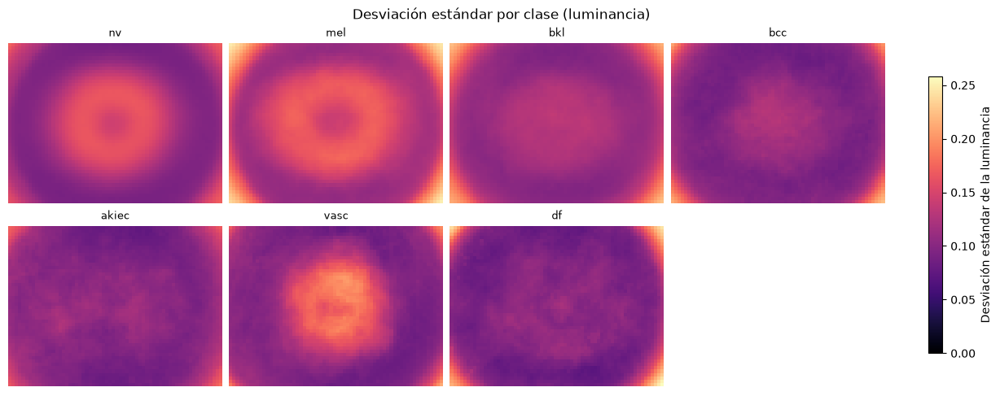

In [59]:
std_dx = {k: v["std_lum"] for k, v in por_dx.items()}
eda.plot_maps(std_dx, ncols_mapas, "magma", 0, eda.max_value(std_dx), "Desviación estándar de la luminancia",
              suptitle="Desviación estándar por clase (luminancia)")
plt.show()

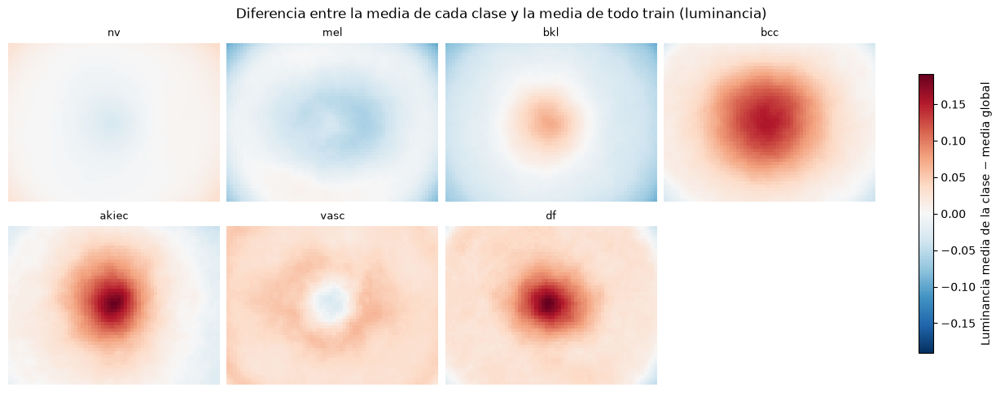

In [60]:
dif_dx = {k: v["media_lum"] - glob["media_lum"] for k, v in por_dx.items()}
lim_dx = eda.symmetric_limit(dif_dx)
eda.plot_maps(dif_dx, ncols_mapas, "RdBu_r", -lim_dx, lim_dx, "Luminancia media de la clase − media global",
              suptitle="Diferencia entre la media de cada clase y la media de todo train (luminancia)")
plt.show()

### 9.3 Por fuente

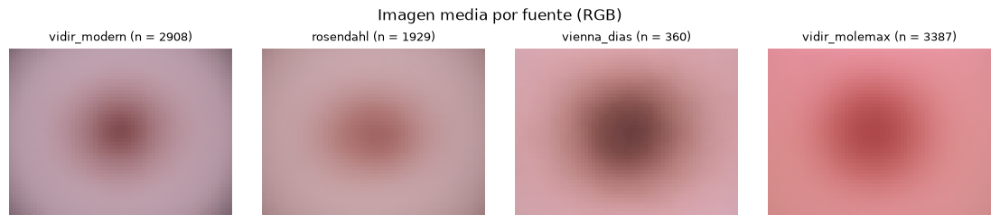

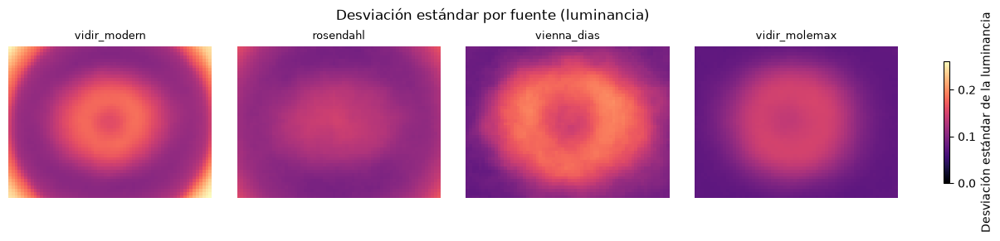

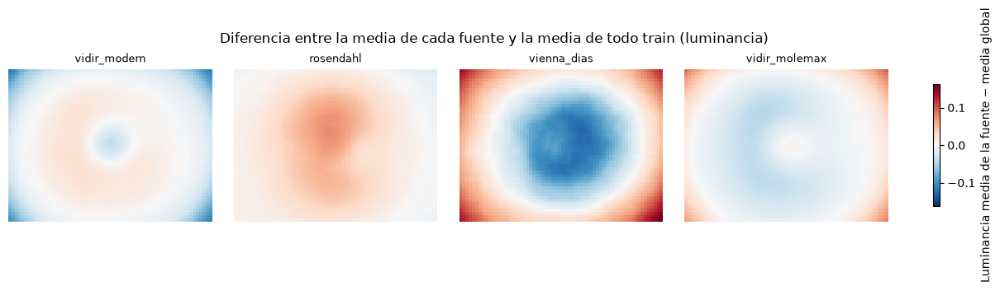

In [61]:
if tiene_fuente:
    por_fuente = img_stats[fuente]
    eda.plot_rgb_grid({f"{k} (n = {v['n']})": v["media_rgb"] for k, v in por_fuente.items()}, ncols_mapas,
                      suptitle="Imagen media por fuente (RGB)")
    plt.show()
    std_f = {k: v["std_lum"] for k, v in por_fuente.items()}
    eda.plot_maps(std_f, ncols_mapas, "magma", 0, eda.max_value(std_f), "Desviación estándar de la luminancia",
                  suptitle="Desviación estándar por fuente (luminancia)")
    plt.show()
    dif_f = {k: v["media_lum"] - glob["media_lum"] for k, v in por_fuente.items()}
    lim_f = eda.symmetric_limit(dif_f)
    eda.plot_maps(dif_f, ncols_mapas, "RdBu_r", -lim_f, lim_f, "Luminancia media de la fuente − media global",
                  suptitle="Diferencia entre la media de cada fuente y la media de todo train (luminancia)")
    plt.show()
else:
    display(pd.DataFrame({"aviso": [f"No existe la columna '{fuente}'."]}))

## 10. Correlación de Spearman

Solo train. Edad, color por imagen (6.2), fracción de área, distancia del centroide y
diferencia de luminancia lesión − fondo (7) y los dos indicadores de viñeteado (4.3).
Correlación de Spearman con observaciones completas por pares; heatmap con escala
divergente centrada en 0 y los `eda_spearman_top_pairs` pares con mayor correlación
absoluta.

In [62]:
vars_spearman = ["age", *vars_color, "fraccion_area", "dist_centroide", "dif_luminancia", *vars_vin]
tabla_sp = (train[["image_id", "age"]]
            .merge(color_img[["image_id", *vars_color]], on="image_id", how="left")
            .merge(les[["image_id", "fraccion_area", "dist_centroide", "dif_luminancia"]], on="image_id", how="left")
            .merge(vin[["image_id", *vars_vin]], on="image_id", how="left"))
assert len(tabla_sp) == len(train)
corr_sp = stats.spearman_matrix(tabla_sp, vars_spearman)

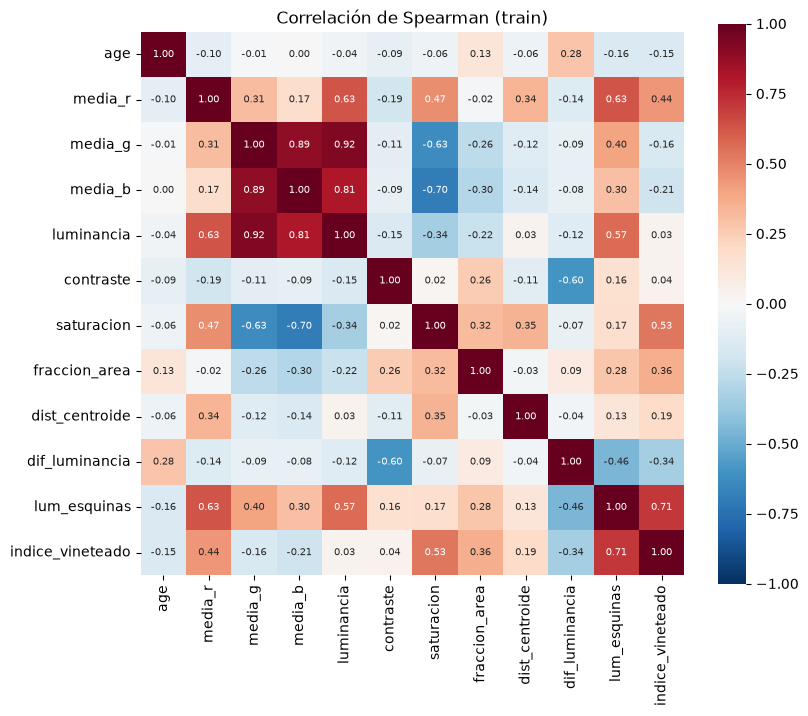

In [63]:
eda.plot_corr_heatmap(corr_sp, "Correlación de Spearman (train)")
plt.show()

In [64]:
stats.top_correlations(corr_sp, cfg["eda_spearman_top_pairs"])

,variable_1,variable_2,rho,abs_rho
0,media_g,luminancia,0.924863,0.924863
1,media_g,media_b,0.886876,0.886876
2,media_b,luminancia,0.807682,0.807682
3,lum_esquinas,indice_vineteado,0.706527,0.706527
4,media_b,saturacion,-0.699816,0.699816
5,media_r,lum_esquinas,0.631999,0.631999
6,media_g,saturacion,-0.631353,0.631353
7,media_r,luminancia,0.629980,0.629980
8,contraste,dif_luminancia,-0.597732,0.597732
9,luminancia,lum_esquinas,0.568964,0.568964


## 11. Valores atípicos en las características de imagen

Solo train. Variables: color por imagen (6.2), nitidez (5), porcentaje de recorte por
canal (6.4), fracción de área, distancia del centroide y diferencia de luminancia
lesión − fondo (7), indicadores de viñeteado (4.3) y tamaño de archivo (5). Solo se
marcan casos; no se elimina ni se modifica ningún dato. La tabla de marcas se guarda en
`data/atipicos_imagenes.csv`.

In [65]:
vars_atip = [*vars_color, "nitidez", *vars_rec, "fraccion_area", "dist_centroide", "dif_luminancia", *vars_vin,
             "tamano_kb"]
tabla_atip = (train[["image_id", "dx", *([fuente] if tiene_fuente else [])]]
              .merge(color_img[["image_id", *vars_color]], on="image_id", how="left")
              .merge(calidad[["image_id", "nitidez", *vars_rec]], on="image_id", how="left")
              .merge(les[["image_id", "fraccion_area", "dist_centroide", "dif_luminancia"]], on="image_id", how="left")
              .merge(vin[["image_id", *vars_vin]], on="image_id", how="left")
              .merge(info[["image_id", "tamano_kb"]], on="image_id", how="left"))
assert len(tabla_atip) == len(train)
pd.Series({"imágenes": len(tabla_atip), "variables": len(vars_atip)}, name="valor").to_frame()

,valor
imágenes,8584
variables,16


### 11.1 Univariado

Por variable: atípicos según la regla de IQR (fuera de [Q1 − `iqr_factor`·IQR,
Q3 + `iqr_factor`·IQR]) y según el z robusto (|0,6745·(x − mediana)/MAD| > `robust_z`;
sin marcas si MAD = 0).

In [66]:
marcas_uni, resumen_uni = stats.univariate_outliers(tabla_atip, vars_atip, cfg["iqr_factor"], cfg["robust_z"])
resumen_uni

,n_validos,limite_inferior_iqr,limite_superior_iqr,atipicos_iqr,pct_iqr,mediana,mad,mad_cero,atipicos_z_robusto,pct_z_robusto
media_r,8584,0.47357,1.057451,15,0.174744,0.772047,0.072091,False,3,0.034949
media_g,8584,0.321234,0.77002,88,1.025163,0.545566,0.056099,False,13,0.151445
media_b,8584,0.320099,0.820541,82,0.955266,0.569187,0.062434,False,10,0.116496
luminancia,8584,0.411091,0.815832,72,0.83877,0.61309,0.050672,False,12,0.139795
contraste,8584,-0.007406,0.218994,194,2.260019,0.102157,0.027431,False,97,1.130009
saturacion,8584,-0.088752,0.697833,1,0.01165,0.290182,0.097095,False,0,0.0
nitidez,8584,-47.132478,171.774966,612,7.129543,49.5238,19.223633,False,829,9.657502
recorte_r,8584,-0.000556,0.000926,1688,19.664492,0.0,0.0,True,0,0.0
recorte_g,8584,0.0,0.0,1654,19.268406,0.0,0.0,True,0,0.0
recorte_b,8584,-0.001111,0.001852,1668,19.4315,0.0,0.0,True,0,0.0


Atípicos por clase, regla de IQR.

In [67]:
por_clase_atip = stats.outlier_counts_by_group(marcas_uni, tabla_atip["dx"], orden_dx)
por_clase_atip["iqr"]

,media_r,media_g,media_b,luminancia,contraste,saturacion,nitidez,recorte_r,recorte_g,recorte_b,fraccion_area,dist_centroide,dif_luminancia,lum_esquinas,indice_vineteado,tamano_kb
nv,7,68,66,53,91,1,346,1003,793,834,82,301,62,301,382,372
mel,5,8,9,11,75,0,102,292,385,379,29,4,45,144,199,38
bkl,3,7,1,5,22,0,97,236,285,257,28,8,26,131,156,53
bcc,0,3,2,1,2,0,38,50,92,100,6,8,3,42,70,55
akiec,0,0,0,0,1,0,10,61,51,58,16,4,5,14,21,12
vasc,0,2,2,2,3,0,8,16,23,12,1,12,4,5,9,2
df,0,0,2,0,0,0,11,30,25,28,2,4,0,9,20,7


Atípicos por clase, z robusto.

In [68]:
por_clase_atip["z_robusto"]

,media_r,media_g,media_b,luminancia,contraste,saturacion,nitidez,recorte_r,recorte_g,recorte_b,fraccion_area,dist_centroide,dif_luminancia,lum_esquinas,indice_vineteado,tamano_kb
nv,0,8,9,8,41,0,487,0,0,0,40,224,14,219,497,162
mel,3,3,0,2,43,0,133,0,0,0,15,3,3,127,242,10
bkl,0,0,0,0,11,0,126,0,0,0,13,6,12,104,201,9
bcc,0,0,0,0,1,0,46,0,0,0,3,6,1,21,85,30
akiec,0,0,0,0,0,0,12,0,0,0,6,3,0,10,32,7
vasc,0,2,1,2,1,0,9,0,0,0,1,10,1,0,15,2
df,0,0,0,0,0,0,16,0,0,0,0,3,0,7,22,2


### 11.2 Multicolinealidad

Para las variables que usa la distancia de Mahalanobis (MAD > 0): factor de inflación de
la varianza (statsmodels, variables estandarizadas con constante) y número de condición
de su matriz de correlación. Filas sin faltantes. Tabla ordenada por VIF.

In [69]:
vars_mahal, _ = stats.mahalanobis_variables(tabla_atip, vars_atip)
vif, resumen_vif = stats.vif_table(tabla_atip, vars_mahal)
display(pd.Series(resumen_vif, name="valor").to_frame())
vif

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/src/stats.py:285: UserWarning: The design matrix is poorly conditioned (condition number=5.58e+11). VIF calculations may be numerically unstable.
  vif = [float(variance_inflation_factor(Zc, i + 1)) for i in range(len(cols))]


,valor
variables,1.300000e+01
filas_completas,8.581000e+03
numero_condicion,3.636552e+17
autovalor_minimo,5.372217e-16
autovalor_maximo,3.846060e+00


,vif
variable,
media_r,1.000800e+15
media_g,1.000800e+15
media_b,1.000800e+15
luminancia,1.000800e+15
lum_esquinas,5.104496e+01
saturacion,3.846243e+01
indice_vineteado,3.669833e+01
contraste,5.090693e+00
dif_luminancia,3.481014e+00


### 11.3 Multivariado

Distancia de Mahalanobis robusta al cuadrado (MinCovDet sobre las variables
estandarizadas); umbral en el cuantil `mahal_quantile` de la chi-cuadrado. Se usan las
variables con MAD > 0 y las filas sin faltantes en ellas.

In [70]:
mahal, info_mahal = stats.robust_mahalanobis(tabla_atip, vars_atip, cfg["mahal_quantile"], cfg["seed"])
tabla_atip = tabla_atip.drop(columns=mahal.columns, errors="ignore").join(mahal)
pd.Series(info_mahal, name="valor").to_frame()

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:793: UserWarning: The covariance matrix associated to your dataset is not full rank
  warnings.warn(
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-63.001344239242506 > -63.687729740966198). You may want to try with a higher value of support_fraction (current value: 0.503).
  warnings.warn(
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-60.663420735572885 > -61.745640997504054). You may want to try with a higher value of support_fr

,valor
variables_usadas,"media_r, media_g, media_b, luminancia, contras..."
variables_excluidas_mad_cero,"recorte_r, recorte_g, recorte_b"
filas_completas,8581
filas_con_faltantes,3
cuantil,0.975
umbral_d2,24.735605
atipicos,2962


In [71]:
eda.flag_table(tabla_atip, "atipico_mahal", "dx", orden_dx)

,imagenes,marcadas,pct_marcadas
dx,,,
nv,5747,1605,27.927614
mel,954,484,50.733753
bkl,942,435,46.178344
bcc,440,216,49.090909
akiec,281,134,47.686833
vasc,122,46,37.704918
df,98,42,42.857143
Total,8584,2962,34.506058


In [72]:
if tiene_fuente:
    display(eda.flag_table(tabla_atip, "atipico_mahal", fuente))
else:
    display(pd.DataFrame({"aviso": [f"No existe la columna '{fuente}'."]}))

,imagenes,marcadas,pct_marcadas
dataset,,,
rosendahl,1929,730,37.843442
vidir_modern,2908,1536,52.819807
vidir_molemax,3387,535,15.795689
vienna_dias,360,161,44.722222
Total,8584,2962,34.506058


Las `eda_outlier_grid_n` imágenes con mayor distancia de Mahalanobis.

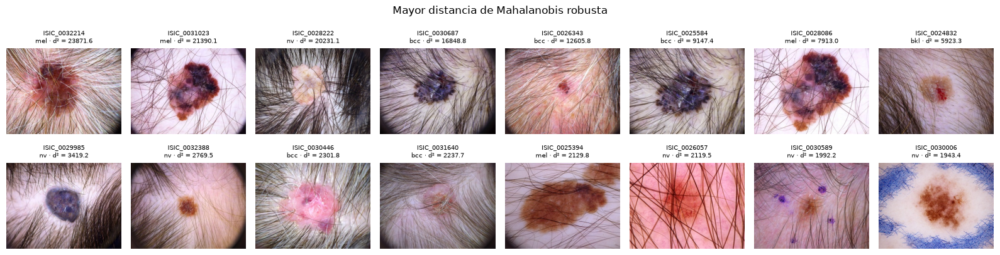

In [73]:
top_mahal = tabla_atip.nlargest(cfg["eda_outlier_grid_n"], "mahal_d2")
eda.plot_image_grid(top_mahal["image_id"].map(cache),
                    top_mahal["image_id"] + "\n" + top_mahal["dx"] + " · d² = " + top_mahal["mahal_d2"].round(1).astype(str),
                    ncols=cfg["eda_grid_ncols"], suptitle="Mayor distancia de Mahalanobis robusta")
plt.show()

Tabla de marcas: una fila por imagen, con las marcas univariadas, su número y la distancia de Mahalanobis.

In [74]:
atipicos = pd.concat([tabla_atip[["image_id", "dx", *([fuente] if tiene_fuente else [])]], marcas_uni,
                      tabla_atip[["mahal_d2", "atipico_mahal"]]], axis=1)
atipicos.insert(len(atipicos.columns) - 2, "n_marcas_univariadas", marcas_uni.sum(axis=1))
atipicos.to_csv(rutas["outliers_csv"], index=False)
pd.Series({"archivo": str(rutas["outliers_csv"]), "filas": len(atipicos), "columnas": atipicos.shape[1]},
          name="valor").to_frame()

,valor
archivo,/var/home/luencaro/Programing/College/2026-30/...
filas,8584
columnas,38


## 12. Desplazamiento de covariables (validación adversarial)

Histogramas de color de `adv_hist_bins` intervalos por canal para las imágenes de train y
de test de `splits.csv`. De test solo se usa el `image_id`, no las etiquetas. Una
regresión logística con validación cruzada estratificada de `adv_cv_folds` pliegues
predice si cada imagen es de test; se reporta el AUC medio y su desviación estándar.

In [75]:
ids_test_lista = splits.loc[splits["split"] == "test", "image_id"].tolist()
ids_adv = train["image_id"].tolist() + ids_test_lista
y_adv = np.r_[np.zeros(len(train), dtype=int), np.ones(len(ids_test_lista), dtype=int)]
X_adv = eda.color_histograms(data.image_paths(cfg, ids_adv), cfg["adv_hist_bins"])
pd.Series({"imágenes": X_adv.shape[0], "características": X_adv.shape[1],
           "train (y = 0)": int((y_adv == 0).sum()), "test (y = 1)": int((y_adv == 1).sum())},
          name="valor").to_frame()

Histogramas: 100%|██████████| 10015/10015 [01:26<00:00, 115.20it/s]


,valor
imágenes,10015
características,48
train (y = 0),8584
test (y = 1),1431


In [76]:
res_adv = eda.adversarial_validation(X_adv, y_adv, cfg["adv_cv_folds"], cfg["seed"], cfg["adv_max_iter"])
res_adv

{'auc_media': 0.4830792432515517,
 'auc_std': 0.014336872859298933,
 'auc_por_pliegue': [0.4925528751970219,
  0.4759582293070936,
  0.4610761981175493,
  0.49440803808887673,
  0.491400875547217]}

## 13. Embeddings

Solo si `eda_embeddings` es `true`. Características de MobileNetV2 preentrenada en
ImageNet (`keras.applications`, con su `preprocess_input`) sobre la caché de
entrenamiento, proyectadas a 2D con t-SNE y coloreadas por `dx` y por fuente. Los
embeddings se guardan en `embeddings_cache` (`data/processed/`) y se reutilizan si
corresponden a las mismas imágenes y al mismo tamaño de entrada. La primera ejecución
descarga los pesos de Keras.

In [77]:
emb = None
proy = None
if cfg["eda_embeddings"]:
    emb = eda.load_or_compute_embeddings(rutas["embeddings_cache"], train["image_id"], train["cache_path"],
                                         cfg["eda_embeddings_input_size"], cfg["eda_embeddings_batch_size"])
    xy = eda.tsne_2d(emb, cfg["seed"], cfg["eda_tsne_perplexity"])
    proy = train[["image_id", "dx", *([fuente] if tiene_fuente else [])]].assign(tsne_1=xy[:, 0], tsne_2=xy[:, 1])
    display(pd.Series({"imágenes": emb.shape[0], "dimensiones": emb.shape[1]}, name="valor").to_frame())
else:
    display(pd.DataFrame({"aviso": ["eda_embeddings es false: se omite esta sección."]}))

I0000 00:00:1794592835.133516  106494 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4193 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 16s 2us/step


Embeddings: 100%|██████████| 135/135 [00:32<00:00,  4.10it/s]


,valor
imágenes,8584
dimensiones,1280


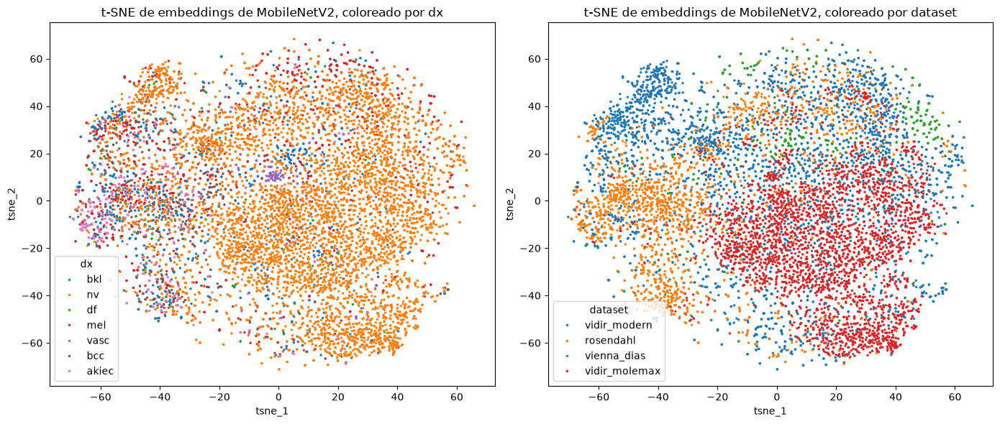

In [78]:
if proy is not None:
    eda.plot_scatter_2d(proy, "tsne_1", "tsne_2", ["dx", *([fuente] if tiene_fuente else [])],
                        "t-SNE de embeddings de MobileNetV2")
    plt.show()

### 13.1 Separabilidad lineal

Regresión logística multinomial (`class_weight="balanced"`, `emb_probe_max_iter`
iteraciones) sobre los embeddings estandarizados, evaluada con los 5 pliegues de la
columna `fold` de `data/splits.csv` (solo train). Exactitud balanceada, F1 macro y
exactitud por pliegue, con media y desviación estándar; matriz de confusión normalizada
por fila con las predicciones fuera de pliegue de todos los pliegues.

In [79]:
sep_dx = None
if emb is not None:
    sep_dx = eda.fold_cv_classification(emb, train["dx"], train["fold"], cfg["emb_probe_max_iter"])
    display(pd.Series({"clases": sep_dx["n_clases"], "azar (1 / clases)": sep_dx["azar"]}, name="valor").to_frame())
    display(sep_dx["pliegues"])

,valor
clases,7.000000
azar (1 / clases),0.142857


,exactitud_balanceada,f1_macro,exactitud,n
fold,,,,
0,0.480194,0.477145,0.674432,1717.0
1,0.471526,0.460530,0.688410,1717.0
2,0.493490,0.491093,0.680839,1717.0
3,0.440636,0.443627,0.675015,1717.0
4,0.507011,0.501848,0.691725,1716.0
media,0.478571,0.474849,0.682084,NaN
desviación estándar,0.025113,0.023334,0.007795,NaN


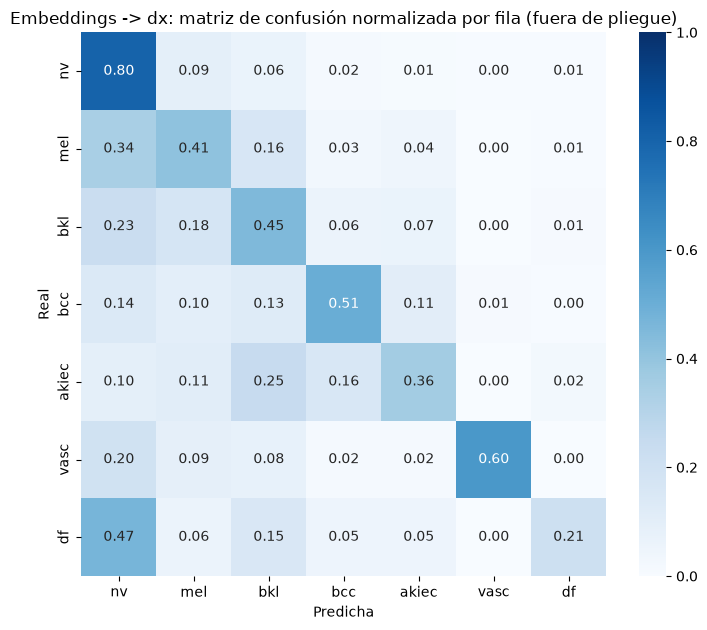

In [80]:
if sep_dx is not None:
    eda.plot_confusion(train["dx"], sep_dx["oof"], orden_dx,
                       "Embeddings -> dx: matriz de confusión normalizada por fila (fuera de pliegue)")
    plt.show()

La misma regresión con la fuente como etiqueta en lugar de `dx`.

In [81]:
if emb is not None and tiene_fuente:
    sep_fuente = eda.fold_cv_classification(emb, train[fuente], train["fold"], cfg["emb_probe_max_iter"])
    display(pd.Series({"exactitud_balanceada_media": sep_fuente["exactitud_balanceada_media"],
                       "exactitud_balanceada_std": sep_fuente["exactitud_balanceada_std"],
                       "clases": sep_fuente["n_clases"], "azar (1 / clases)": sep_fuente["azar"]},
                      name=f"embeddings -> {fuente}").to_frame())
elif emb is not None:
    display(pd.DataFrame({"aviso": [f"No existe la columna '{fuente}'."]}))

,embeddings -> dataset
exactitud_balanceada_media,0.829406
exactitud_balanceada_std,0.011564
clases,4.000000
azar (1 / clases),0.250000
